In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ee
import geemap

In [2]:
ee.Authenticate()

True

In [3]:
PROJECT_ID = "sbw-analysis"

ee.Initialize(project=PROJECT_ID)
print("Earth Engine initialized successfully with project:", PROJECT_ID)

Earth Engine initialized successfully with project: sbw-analysis


In [4]:
os.makedirs("data/raw/landsat", exist_ok=True)
os.makedirs("data/raw/shapefiles", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("data/metadata", exist_ok=True)

print("Project folders created.")

Project folders created.


In [5]:
mask_path = "data/MI_Bounds_UP/MI_Bounds_UP.shp"
up_mask = gpd.read_file(mask_path)

print("Mask CRS:", up_mask.crs)
print("Mask extent:", up_mask.total_bounds)

Mask CRS: EPSG:4326
Mask extent: [-90.418392    45.09481536 -83.47286174  48.23856901]


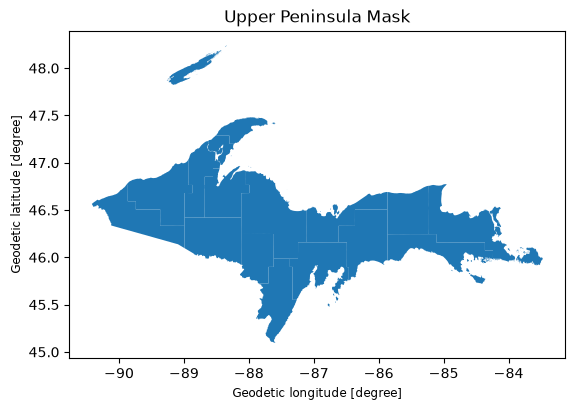

In [6]:
up_mask.plot()
plt.title("Upper Peninsula Mask")
plt.show()

In [7]:
# ## 3. Load USFS ADS Shapefile (Spruce Budworm)

# %%
ads_path = "data/raw/shapefiles/ADS_SBW_Michigan.shp"
ads = gpd.read_file(ads_path)

ads_sbw = ads[ads['AGENT'].str.contains('budworm', case=False, na=False)].copy()

print(f"Total ADS polygons: {len(ads)}")
print(f"Spruce Budworm polygons: {len(ads_sbw)}")
ads_sbw.head()

DataSourceError: data/raw/shapefiles/ADS_SBW_Michigan.shp: No such file or directory

In [7]:
study_area = geemap.geopandas_to_ee(up_mask)

landsat = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
           .merge(ee.ImageCollection('LANDSAT/LC09/C02/T1_L2'))
           .filterBounds(study_area)
           .filterDate('2020-05-15', '2024-07-31')
           .filter(ee.Filter.lt('CLOUD_COVER', 20))
           .select(['SR_B2','SR_B3','SR_B4','SR_B5','SR_B6','SR_B7']))

print("Number of Landsat scenes:", landsat.size().getInfo())

Number of Landsat scenes: 597


In [8]:
median = landsat.median().clip(study_area)

Map = geemap.Map()
Map.addLayer(median, 
             {'bands': ['SR_B4','SR_B3','SR_B2'], 'min': 0, 'max': 3000, 'gamma': 1.4},
             'Landsat Median RGB')
Map.add_gdf(up_mask, layer_name="UP Mask", style={"color": "red", "fill": "none"})
Map.centerObject(study_area, zoom=7)
Map

Map(center=[46.36325652285133, -87.33130656860408], controls=(WidgetControl(options=['position', 'transparent_…

In [9]:
from shapely.geometry import box

os.makedirs("data/processed/landsat/tiles", exist_ok=True)
study_area_ee = geemap.geopandas_to_ee(up_mask).geometry()


# 1. Create a grid of tiles (~0.4° × 0.4° ≈ 40 km tiles)
tile_size = 0.25
bounds = up_mask.total_bounds          # [minx, miny, maxx, maxy]
minx, miny, maxx, maxy = bounds

tiles = []
x = minx
while x < maxx:
    y = miny
    while y < maxy:
        tile = box(x, y, x + tile_size, y + tile_size)
        tiles.append(tile)
        y += tile_size
    x += tile_size

tile_gdf = gpd.GeoDataFrame(geometry=tiles, crs=up_mask.crs)
tile_gdf = tile_gdf[tile_gdf.intersects(up_mask.geometry.unary_union)].reset_index(drop=True)

print(f"Number of tiles: {len(tile_gdf)}")

# 2. Export each tile for each year
years = list(range(2020, 2025))

for year in years:
    print(f"\n=== Exporting year {year} ===")
    
    yearly_median = (landsat
                     .filterDate(f'{year}-05-15', f'{year}-07-31')
                     .median()
                     .clip(study_area_ee))
    
    for idx, row in tile_gdf.iterrows():
        tile_geom = ee.Geometry.Rectangle(list(row.geometry.bounds))
        export_path = f"data/processed/landsat/tiles/UP_{year}_tile_{idx:03d}.tif"
        
        print(f"  Tile {idx+1}/{len(tile_gdf)} …", end=" ")
        
        try:
            geemap.ee_export_image(
                yearly_median.clip(tile_geom),
                filename=export_path,
                scale=30,
                region=tile_geom,
                file_per_band=False,
                crs='EPSG:5070'
            )
            print("done")
        except Exception as e:
            print(f"ERROR: {e}")

print("\nAll yearly tiled exports finished.")

Number of tiles: 139

=== Exporting year 2020 ===
  Tile 1/139 … Generating URL ...


KeyboardInterrupt: 

In [ ]:
from rasterio.merge import merge
from rasterio.plot import show
import glob

os.makedirs("data/processed/landsat/merged", exist_ok=True)

years = list(range(2020, 2025))

for year in years:
    print(f"Mosaicking year {year} …")
    
    # Find all tiles for this year
    tile_pattern = f"data/processed/landsat/tiles/UP_{year}_tile_*.tif"
    tile_files = glob.glob(tile_pattern)
    
    if not len(tile_files):
        print(f"  No tiles found for {year}")
        continue
    
    # Open all tile datasets
    src_files = [rasterio.open(f) for f in tile_files]
    
    # Merge them
    mosaic, out_trans = merge(src_files)
    
    # Copy metadata from first tile
    out_meta = src_files[0].meta.copy()
    out_meta.update({
        "driver": "GTiff",
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": out_trans,
        "crs": src_files[0].crs
    })
    
    # Save merged raster
    out_path = f"data/processed/landsat/merged/UP_Landsat_Median_{year}.tif"
    with rasterio.open(out_path, "w", **out_meta) as dest:
        dest.write(mosaic)
    
    # Close all tile files
    for src in src_files:
        src.close()
    
    print(f"  Saved merged file: {out_path}")

print("\nAll years mosaicked successfully!")

In [ ]:
os.makedirs("data/metadata", exist_ok=True)

up_mask.to_file("data/metadata/up_mask.geojson", driver="GeoJSON")
ads_sbw.to_file("data/metadata/ads_sbw.geojson", driver="GeoJSON")

with open("data/metadata/data_acquisition_log.txt", "w") as f:
    f.write(f"Project ID: {PROJECT_ID}\n")
    f.write(f"Landsat scenes: {landsat.size().getInfo()}\n")
    f.write(f"Exported median: {export_path}\n")

print("Data acquisition complete. All files saved on the server.")
